In [1]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, GridSearchCV, RandomizedSearchCV, cross_val_score, StratifiedKFold

from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler

from sklearn.svm import SVC, SVR
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

In [2]:
df = pd.read_csv(r'/Users/pawn/Desktop/NTI/bank.csv')
df

,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,deposit
0,59,admin.,married,secondary,no,2343.0,yes,no,unknown,5.0,may,1042.0,1.0,-1.0,0.0,unknown,yes
1,56,admin.,married,secondary,no,45.0,no,no,unknown,5.0,may,1467.0,1.0,-1.0,0.0,unknown,yes
2,41,technician,married,secondary,no,1270.0,yes,no,unknown,5.0,may,1389.0,1.0,-1.0,0.0,unknown,yes
3,54,admin.,married,tertiary,no,184.0,no,no,unknown,5.0,may,673.0,2.0,-1.0,0.0,unknown,yes
4,42,management,single,tertiary,no,0.0,yes,yes,unknown,5.0,may,562.0,2.0,-1.0,0.0,unknown,yes
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
8907,33,blue-collar,single,primary,no,1.0,yes,no,cellular,20.0,apr,257.0,1.0,-1.0,0.0,unknown,no
8908,39,services,married,secondary,no,733.0,no,no,unknown,16.0,jun,83.0,4.0,-1.0,0.0,unknown,no
8909,32,technician,single,secondary,no,29.0,no,no,cellular,19.0,aug,156.0,2.0,-1.0,0.0,unknown,no
8910,43,technician,married,secondary,no,0.0,no,yes,cellular,8.0,may,9.0,2.0,172.0,5.0,failure,no


In [3]:
df.shape

(8912, 17)

In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8912 entries, 0 to 8911
Data columns (total 17 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   age        8912 non-null   int64  
 1   job        8905 non-null   object 
 2   marital    8743 non-null   object 
 3   education  8885 non-null   object 
 4   default    8908 non-null   object 
 5   balance    8899 non-null   float64
 6   housing    8899 non-null   object 
 7   loan       8882 non-null   object 
 8   contact    8881 non-null   object 
 9   day        8893 non-null   float64
 10  month      8884 non-null   object 
 11  duration   8905 non-null   float64
 12  campaign   8904 non-null   float64
 13  pdays      8767 non-null   float64
 14  previous   8909 non-null   float64
 15  poutcome   8912 non-null   object 
 16  deposit    8903 non-null   object 
dtypes: float64(6), int64(1), object(10)
memory usage: 1.2+ MB


In [5]:
df.describe()

,age,balance,day,duration,campaign,pdays,previous
count,8912.000000,8899.000000,8893.000000,8905.000000,8904.000000,8767.000000,8909.000000
mean,41.257855,1539.680638,15.684921,374.953734,2.512579,52.456941,0.834325
std,11.840567,3297.446702,8.406729,351.283501,2.772366,109.094161,2.304733
min,18.000000,-3058.000000,1.000000,3.000000,1.000000,-1.000000,0.000000
25%,32.000000,121.500000,8.000000,139.000000,1.000000,-1.000000,0.000000
50%,39.000000,553.000000,15.000000,256.000000,2.000000,-1.000000,0.000000
75%,49.000000,1726.000000,22.000000,501.000000,3.000000,64.000000,1.000000
max,95.000000,81204.000000,31.000000,3284.000000,63.000000,842.000000,58.000000


In [6]:
df.duplicated().sum()

0

In [7]:
df.isnull().sum().sort_values(ascending = False)

marital      169
pdays        145
contact       31
loan          30
month         28
education     27
day           19
balance       13
housing       13
deposit        9
campaign       8
job            7
duration       7
default        4
previous       3
poutcome       0
age            0
dtype: int64

In [8]:
df.select_dtypes(include=['object']).columns

Index(['job', 'marital', 'education', 'default', 'housing', 'loan', 'contact',
       'month', 'poutcome', 'deposit'],
      dtype='object')

<Axes: >

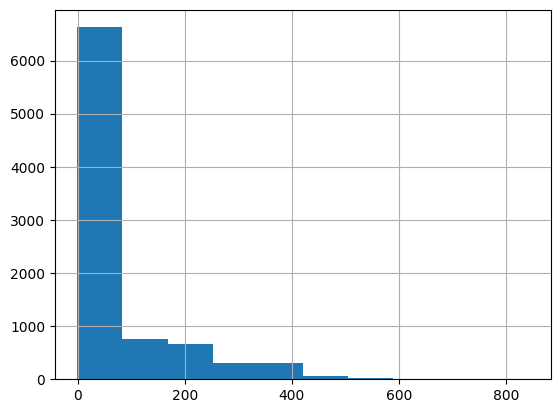

In [9]:
df['pdays'].hist()

In [10]:
df['pdays'].skew()

2.3600576727470965

In [11]:
from sklearn.impute import SimpleImputer

df.replace("?", np.nan, inplace=True)
df.dropna(subset=['deposit'], inplace=True)

numeric_columns = df.select_dtypes(include=np.number).columns
categorical_columns = df.select_dtypes(include='object').columns.drop('deposit')

numeric_imputer = SimpleImputer(missing_values=np.nan, strategy='median')
categorical_imputer = SimpleImputer(missing_values=np.nan, strategy='most_frequent')

df[numeric_columns] = numeric_imputer.fit_transform(df[numeric_columns])
df[categorical_columns] = categorical_imputer.fit_transform(df[categorical_columns])

In [12]:
df.select_dtypes(include=['object']).columns

Index(['job', 'marital', 'education', 'default', 'housing', 'loan', 'contact',
       'month', 'poutcome', 'deposit'],
      dtype='object')

<Axes: >

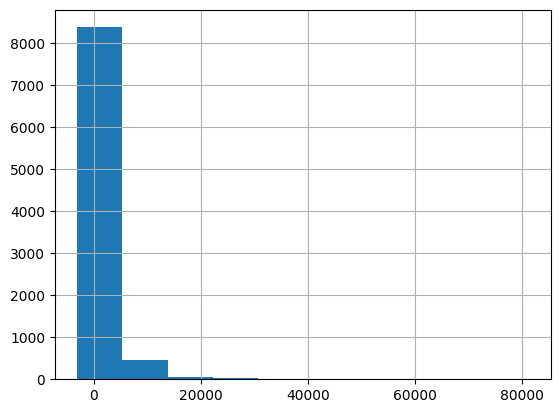

In [13]:
df['balance'].hist()

In [14]:
df.isnull().sum().sort_values(ascending = False)

age          0
day          0
poutcome     0
previous     0
pdays        0
campaign     0
duration     0
month        0
contact      0
job          0
loan         0
housing      0
balance      0
default      0
education    0
marital      0
deposit      0
dtype: int64

In [15]:
from sklearn.preprocessing import OneHotEncoder

In [16]:
onhot = OneHotEncoder(
                      sparse_output=False,
                      drop='first',
                      handle_unknown='ignore'
).set_output(transform='pandas')

In [17]:
for col in df.select_dtypes('object').columns:
    print(f"{col} number unique: ",df[col].nunique())
    print("-"*50)

job number unique:  12
--------------------------------------------------
marital number unique:  3
--------------------------------------------------
education number unique:  4
--------------------------------------------------
default number unique:  2
--------------------------------------------------
housing number unique:  2
--------------------------------------------------
loan number unique:  2
--------------------------------------------------
contact number unique:  3
--------------------------------------------------
month number unique:  12
--------------------------------------------------
poutcome number unique:  4
--------------------------------------------------
deposit number unique:  2
--------------------------------------------------


In [18]:
df.select_dtypes(include=['object']).columns

Index(['job', 'marital', 'education', 'default', 'housing', 'loan', 'contact',
       'month', 'poutcome', 'deposit'],
      dtype='object')

In [19]:
for col in ['job', 'marital', 'education', 'default', 'housing', 'loan', 'contact',
       'month', 'poutcome']:
    temp = onhot.fit_transform(df[[col]])
    df = pd.concat([df, temp], axis=1)


In [20]:

df.drop(['job', 'marital', 'education', 'default', 'housing', 'loan', 'contact',
       'month', 'poutcome'],
        axis=1, inplace=True)

In [21]:
df.head(10)

,age,balance,day,duration,campaign,pdays,previous,deposit,job_blue-collar,job_entrepreneur,...,month_jul,month_jun,month_mar,month_may,month_nov,month_oct,month_sep,poutcome_other,poutcome_success,poutcome_unknown
0,59.0,2343.0,5.0,1042.0,1.0,-1.0,0.0,yes,0.0,0.0,...,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0
1,56.0,45.0,5.0,1467.0,1.0,-1.0,0.0,yes,0.0,0.0,...,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0
2,41.0,1270.0,5.0,1389.0,1.0,-1.0,0.0,yes,0.0,0.0,...,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0
3,54.0,184.0,5.0,673.0,2.0,-1.0,0.0,yes,0.0,0.0,...,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0
4,42.0,0.0,5.0,562.0,2.0,-1.0,0.0,yes,0.0,0.0,...,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0
5,56.0,830.0,6.0,1201.0,1.0,-1.0,0.0,yes,0.0,0.0,...,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0
6,60.0,545.0,6.0,1030.0,1.0,-1.0,0.0,yes,0.0,0.0,...,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0
7,37.0,1.0,6.0,608.0,1.0,-1.0,0.0,yes,0.0,0.0,...,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0
8,28.0,5090.0,6.0,1297.0,3.0,-1.0,0.0,yes,0.0,0.0,...,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0
9,38.0,100.0,7.0,786.0,1.0,-1.0,0.0,yes,0.0,0.0,...,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0


In [22]:
df['age'].max(), df['age'].min()


(95.0, 18.0)

In [23]:
from sklearn.model_selection import train_test_split

# Target is the income column
X = df.drop(columns=['deposit'])
y = df['deposit']

# Train-test split
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    # stratify=y
)

print('X_train shape =', X_train.shape)
print('X_test shape  =', X_test.shape)
print('y_train shape =', y_train.shape)
print('y_test shape  =', y_test.shape)
print('Target classes:', sorted(y.unique()))


X_train shape = (7122, 42)
X_test shape  = (1781, 42)
y_train shape = (7122,)
y_test shape  = (1781,)
Target classes: ['no', 'yes']


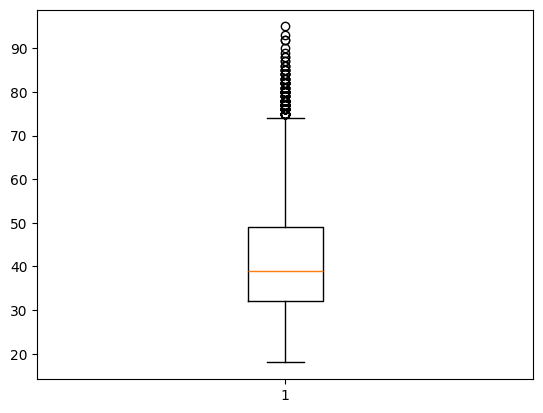

In [24]:
plt.boxplot(df['age'])
plt.show()

In [25]:
from sklearn.linear_model import LogisticRegression

In [26]:
imputer = SimpleImputer(strategy='median')

X_train_imputed = imputer.fit_transform(X_train)
X_test_imputed = imputer.transform(X_test)

In [27]:
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train_imputed)
X_test_scaled = scaler.transform(X_test_imputed)

In [28]:
model = SVC(C=0.1, kernel='linear',gamma='auto')

model.fit(X_train_scaled, y_train)

SVC(C=0.1, gamma='auto', kernel='linear')

In [29]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score , classification_report

In [30]:
y_pred = model.predict(X_test_scaled)

In [31]:
score = accuracy_score(y_test , y_pred)
print(score)

0.8304323413812464


In [32]:
print(accuracy_score(y_test, y_pred))
print(classification_report(y_test, y_pred))


0.8304323413812464
              precision    recall  f1-score   support

          no       0.84      0.85      0.84       946
         yes       0.82      0.81      0.82       835

    accuracy                           0.83      1781
   macro avg       0.83      0.83      0.83      1781
weighted avg       0.83      0.83      0.83      1781



In [33]:
from imblearn.over_sampling import SMOTE
smote = SMOTE(random_state=42)
X_train_smote, y_train_smote = smote.fit_resample(X_train, y_train)
print("X_train_smote = ",X_train_smote.shape ," y_train_smote = ", y_train_smote.shape)

X_train_smote =  (7454, 42)  y_train_smote =  (7454,)


In [34]:
y_train_smote.value_counts()

deposit
no     3727
yes    3727
Name: count, dtype: int64

In [35]:
results = []

# Logistic Regression
model = LogisticRegression()
model.fit(X_train, y_train)
y_pred = model.predict(X_test)

results.append({
    'Method': "Normal Data",
    'Accuracy': accuracy_score(y_test, y_pred),
    # 'Precision': precision_score(y_test, y_pred),
    # 'Recall': recall_score(y_test, y_pred),
    # 'F1-Score': f1_score(y_test, y_pred)
})

/Users/pawn/Library/Python/3.9/lib/python/site-packages/sklearn/linear_model/_logistic.py:469: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. of ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


In [36]:
# Install the imbalanced-learn library if it is not already available
!pip install imbalanced-learn

from imblearn.over_sampling import (
    SMOTE,
    ADASYN,
    RandomOverSampler,
    BorderlineSMOTE,
    SVMSMOTE,
)

# Apply SMOTE to balance the training set
smote = SMOTE(k_neighbors=5, random_state=42)
X_train_smote, y_train_smote = smote.fit_resample(X_train, y_train)

print('X_train_smote =', X_train_smote.shape, 'y_train_smote =', y_train_smote.shape)


zsh:1: command not found: pip


X_train_smote = (7454, 42) y_train_smote = (7454,)


In [37]:
# Logistic Regression Using Smote Over Sampling
model = LogisticRegression()
model.fit(X_train_smote, y_train_smote)
y_pred = model.predict(X_test)

results.append({
    'Method': "SMOTE Over Sampling",
    'Accuracy': accuracy_score(y_test, y_pred),
    # 'Precision': precision_score(y_test, y_pred),
    # 'Recall': recall_score(y_test, y_pred),
    # 'F1-Score': f1_score(y_test, y_pred)
})

/Users/pawn/Library/Python/3.9/lib/python/site-packages/sklearn/linear_model/_logistic.py:469: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. of ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


In [38]:
# Logistic Regression Using Class Weight Balanced

model = LogisticRegression(class_weight='balanced')
model.fit(X_train, y_train)
y_pred = model.predict(X_test)

results.append({
    'Method': "Class Weight Balanced",
    'Accuracy': accuracy_score(y_test, y_pred),
    # 'Precision': precision_score(y_test, y_pred),
    # 'Recall': recall_score(y_test, y_pred),
    # 'F1-Score': f1_score(y_test, y_pred)
})

/Users/pawn/Library/Python/3.9/lib/python/site-packages/sklearn/linear_model/_logistic.py:469: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. of ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


In [39]:
np.unique(y_train)

array(['no', 'yes'], dtype=object)

In [40]:
results_df = pd.DataFrame(results).set_index('Method')
results_df

,Accuracy
Method,
Normal Data,0.789444
SMOTE Over Sampling,0.784391
Class Weight Balanced,0.774846


In [41]:
grid_params = {
    'C': [0.1, 1, 10, 100],
    'kernel': ['linear', 'rbf', 'poly'],
    'gamma': ['auto', 'scale']
}

In [42]:
#!pip install graphviz pydot 
from sklearn.tree import DecisionTreeClassifier, plot_tree

In [43]:
model = DecisionTreeClassifier(
        criterion='gini',
        max_depth=5,
        min_samples_split=10,
        min_samples_leaf=5,
        random_state=100
    )

In [44]:
from sklearn.metrics import  r2_score

In [45]:
model.fit(X_train, y_train)

y_pred_train = model.predict(X_train)
y_pred_test = model.predict(X_test)

print('Train accuracy:', accuracy_score(y_train, y_pred_train))
print('Test accuracy:', accuracy_score(y_test, y_pred_test))
print(classification_report(y_test, y_pred_test))
print('Confusion matrix:')
print(confusion_matrix(y_test, y_pred_test, labels=model.classes_))

Train accuracy: 0.7982308340353833
Test accuracy: 0.7821448624368332
              precision    recall  f1-score   support

          no       0.86      0.70      0.77       946
         yes       0.72      0.87      0.79       835

    accuracy                           0.78      1781
   macro avg       0.79      0.79      0.78      1781
weighted avg       0.80      0.78      0.78      1781

Confusion matrix:
[[663 283]
 [105 730]]


Decision Tree - Plotting the tree


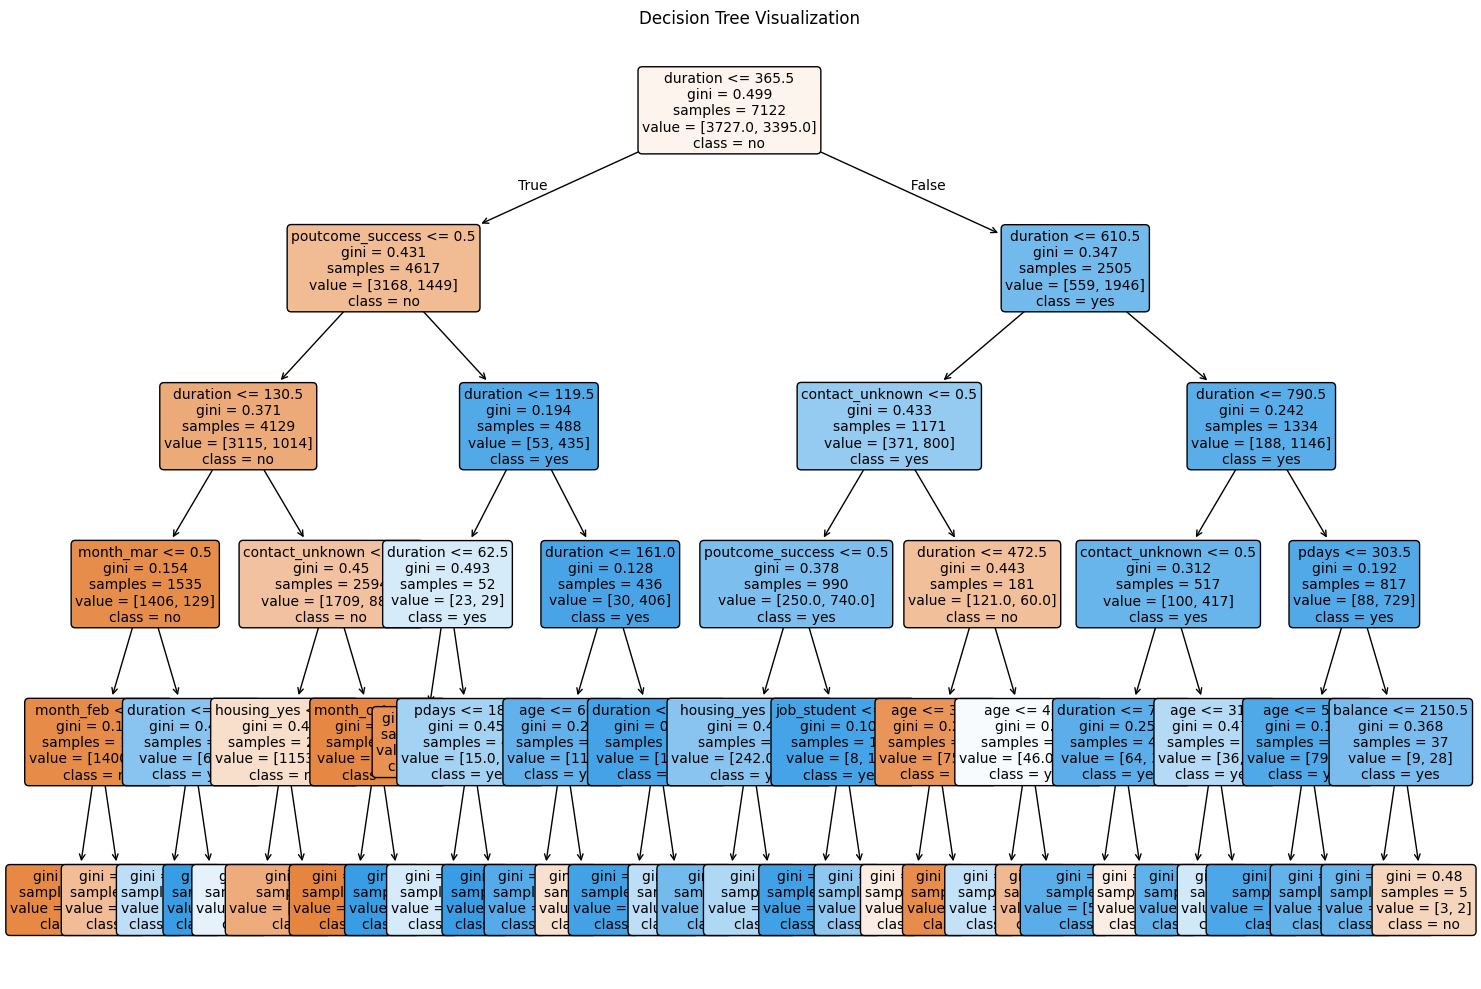

In [46]:
print("Decision Tree - Plotting the tree")

plt.figure(figsize=(15, 10))
plot_tree(
    model,
    feature_names=X.columns.tolist(),
    class_names=[str(c) for c in model.classes_],
    filled=True,
    rounded=True,
    fontsize=10
)
plt.title("Decision Tree Visualization")
plt.tight_layout()
plt.show()

In [47]:
from sklearn.feature_selection import SelectKBest,chi2,f_classif,f_oneway,f_regression

f=SelectKBest(score_func = f_classif, k=10)
X_train_FS=f.fit_transform(X_train,y_train)
X_test_FS=f.transform(X_test)
X_train_FS.shape

(7122, 10)

In [48]:
from sklearn.tree import DecisionTreeClassifier
DT = DecisionTreeClassifier(
        criterion='gini',
        max_depth=5,
        min_samples_split=10,
        min_samples_leaf=5,
        random_state=42,
    )
DT.fit(X_train , y_train)
importances = pd.Series(DT.feature_importances_ , index=X.columns)
importances = importances.sort_values(ascending = False) 
selected_columns = importances.sort_values(ascending = False).index[:5]
print('Descision tree selected Features :' , selected_columns.tolist())
selected_features = importances.nlargest(5)
print('Descision tree selected Features :' , selected_features.tolist())



Descision tree selected Features : ['duration', 'poutcome_success', 'contact_unknown', 'housing_yes', 'month_oct']
Descision tree selected Features : [0.5580527661517904, 0.23165971400151564, 0.11675469978806916, 0.05277546310970887, 0.011314442120602333]


## Additional visualizations (bank marketing)

In [49]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
%matplotlib inline
sns.set_theme(style='whitegrid')
bk = pd.read_csv(r'/Users/pawn/Desktop/NTI/bank.csv')
bk.shape

(8912, 17)

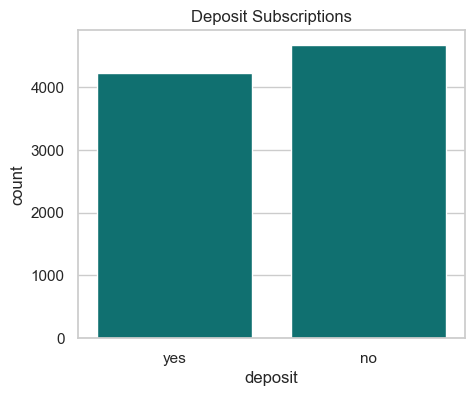

In [50]:
plt.figure(figsize=(5, 4))
sns.countplot(x='deposit', data=bk, color='teal')
plt.title('Deposit Subscriptions')
plt.show()

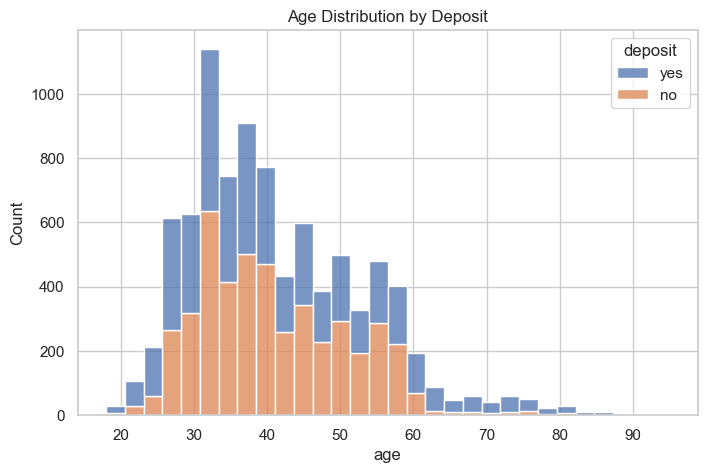

In [51]:
plt.figure(figsize=(8, 5))
sns.histplot(data=bk, x='age', hue='deposit', bins=30, multiple='stack')
plt.title('Age Distribution by Deposit')
plt.show()

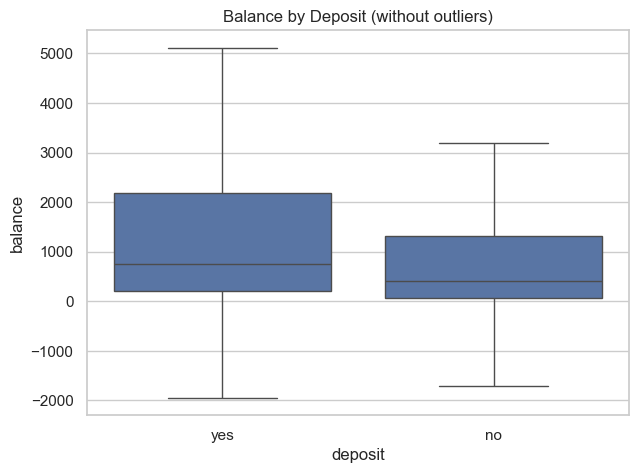

In [52]:
plt.figure(figsize=(7, 5))
sns.boxplot(x='deposit', y='balance', data=bk, showfliers=False)
plt.title('Balance by Deposit (without outliers)')
plt.show()

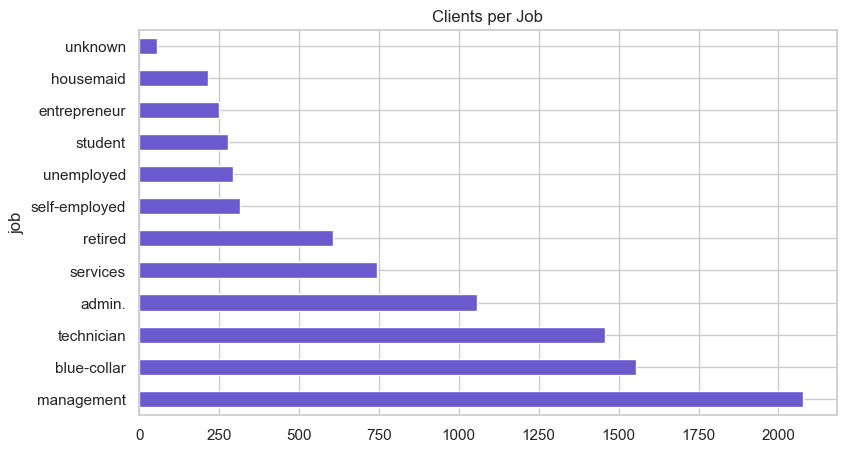

In [53]:
plt.figure(figsize=(9, 5))
bk['job'].value_counts().plot(kind='barh', color='slateblue')
plt.title('Clients per Job')
plt.show()

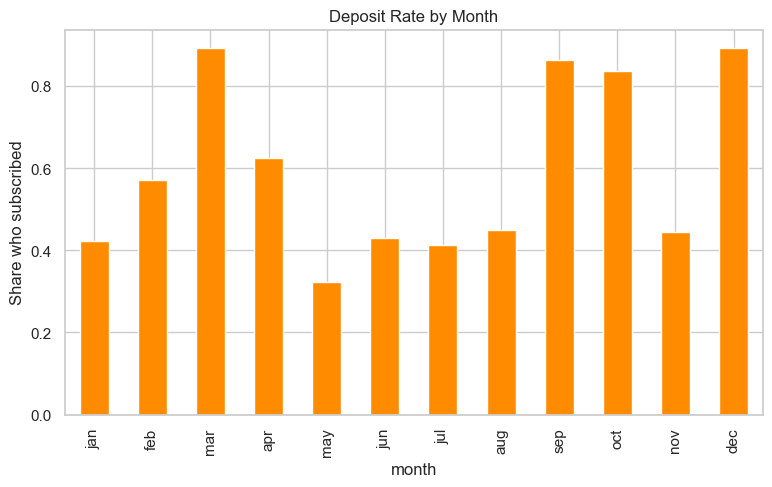

In [54]:
months = ['jan','feb','mar','apr','may','jun','jul','aug','sep','oct','nov','dec']
rate = (bk.assign(d=bk['deposit'].eq('yes')).groupby('month')['d'].mean().reindex(months).dropna())
plt.figure(figsize=(9, 5))
rate.plot(kind='bar', color='darkorange')
plt.title('Deposit Rate by Month')
plt.ylabel('Share who subscribed')
plt.show()

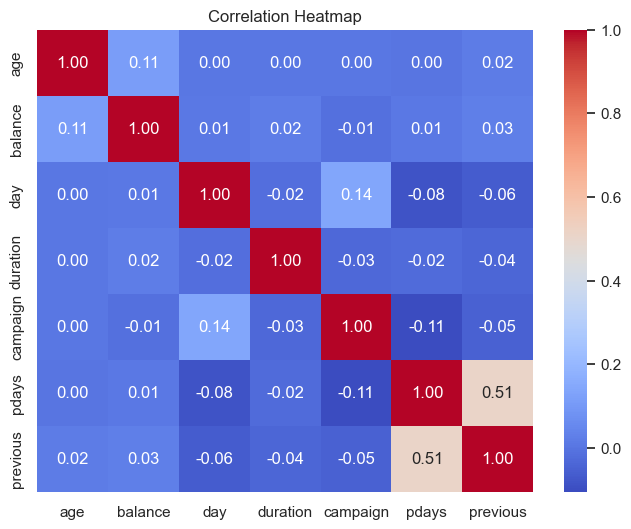

In [55]:
plt.figure(figsize=(8, 6))
sns.heatmap(bk.select_dtypes('number').corr(), annot=True, fmt='.2f', cmap='coolwarm')
plt.title('Correlation Heatmap')
plt.show()